# 01 · Datos y protocolo

Carga de los 5 conjuntos de datos del proyecto, descripción breve, partición 80/20 estratificada, semilla fija y comprobación de que no hay fuga entre entrenamiento y prueba. Esta es la base que usan los notebooks 02 a 05.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from familia3 import SEED
np.random.seed(SEED)
%matplotlib inline


## Breast Cancer Wisconsin (clasificación binaria, caso principal)

In [2]:
from familia3 import datos as D

cancer = D.cargar_breast_cancer()
print("train:", cancer.X_train.shape, "test:", cancer.X_test.shape)
print("balance de clases (train):", np.bincount(cancer.y_train) / len(cancer.y_train))
print("balance de clases (test):", np.bincount(cancer.y_test) / len(cancer.y_test))
print("clases:", cancer.nombres_clases)


train: (455, 30) test: (114, 30)
balance de clases (train): [0.37362637 0.62637363]
balance de clases (test): [0.36842105 0.63157895]
clases: [np.str_('malignant'), np.str_('benign')]


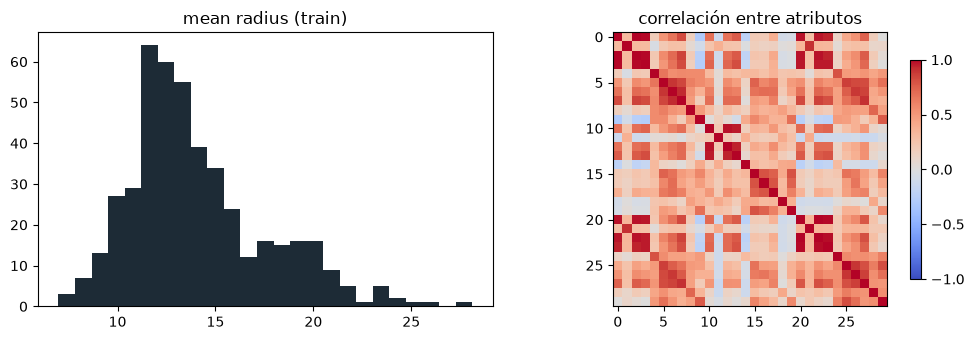

correlación media absoluta entre pares de atributos: 0.3964349862073119


In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(cancer.X_train[:, 0], bins=25, color="#1d2b36")
axes[0].set_title("mean radius (train)")
corr = np.corrcoef(cancer.X_train.T)
im = axes[1].imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("correlación entre atributos")
fig.colorbar(im, ax=axes[1], shrink=0.8)
plt.tight_layout()
plt.savefig("../reports/figuras/01_cancer_eda.png", dpi=150)
plt.show()
print("correlación media absoluta entre pares de atributos:", np.mean(np.abs(corr[np.triu_indices(30, k=1)])))


Los atributos del dataset de cáncer están fuertemente correlacionados (correlación media bastante alta), lo que pone a prueba el supuesto de independencia condicional de Naive Bayes — se retoma en el notebook 02.

## Segundo conjunto de clasificación: Wine (multiclase)

In [4]:
wine = D.cargar_wine()
print("train:", wine.X_train.shape, "clases:", wine.nombres_clases)
print("balance:", np.bincount(wine.y_train) / len(wine.y_train))


train: (142, 13) clases: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
balance: [0.33098592 0.40140845 0.26760563]


## Clasificación sintética 2D: make_moons

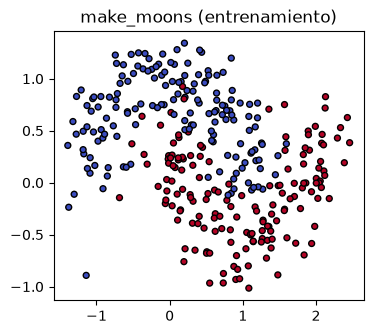

In [5]:
moons = D.sintetico_moons()
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.scatter(moons.X_train[:, 0], moons.X_train[:, 1], c=moons.y_train, cmap="coolwarm", edgecolor="k", s=18)
ax.set_title("make_moons (entrenamiento)")
plt.savefig("../reports/figuras/01_moons.png", dpi=150, bbox_inches="tight")
plt.show()


## Regresión real: Diabetes

In [6]:
diabetes = D.cargar_diabetes()
print("train:", diabetes.X_train.shape, "atributos:", diabetes.nombres_atributos)
print("target: media", diabetes.y_train.mean().round(1), "desviación", diabetes.y_train.std().round(1))


train: (353, 10) atributos: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
target: media 153.7 desviación 78.0


## Regresión sintética 1D: f(x) = sin(x) + ruido, con un hueco deliberado

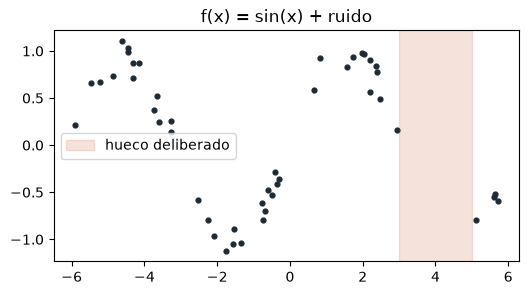

In [7]:
x_train, y_train, x_malla = D.sintetico_seno1d()
fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(x_train, y_train, s=12, color="#1d2b36")
ax.axvspan(3, 5, color="#c1440e", alpha=0.15, label="hueco deliberado")
ax.legend()
ax.set_title("f(x) = sin(x) + ruido")
plt.savefig("../reports/figuras/01_seno1d.png", dpi=150, bbox_inches="tight")
plt.show()


## Comprobación de protocolo: sin fuga de datos

In [8]:
def comprobar_sin_fuga(particion, nombre):
    filas_train = {tuple(np.round(f, 8)) for f in particion.X_train}
    filas_test = {tuple(np.round(f, 8)) for f in particion.X_test}
    interseccion = filas_train & filas_test
    print(f"{nombre}: filas repetidas entre train y test = {len(interseccion)}")
    assert len(interseccion) == 0

for particion, nombre in [(cancer, "breast_cancer"), (wine, "wine"), (moons, "make_moons"), (diabetes, "diabetes")]:
    comprobar_sin_fuga(particion, nombre)
print("\nProtocolo verificado: 80/20 estratificado, SEED=42, sin fuga train/test.")


breast_cancer: filas repetidas entre train y test = 0
wine: filas repetidas entre train y test = 0
make_moons: filas repetidas entre train y test = 0
diabetes: filas repetidas entre train y test = 0

Protocolo verificado: 80/20 estratificado, SEED=42, sin fuga train/test.
